In [1]:
import sys

# Append the parent dir to search path to allow imports from src
sys.path.append('..')

# NOTE: In a real Python file instead use the line below
# sys.path.append(str(Path(__file__).resolve().parent.parent))

# Tell the Notebook to reload changed code in own packages automatically
%load_ext autoreload
%autoreload 2

..\data\raw\train_images\002be4f.jpg (384, 576, 3) uint8


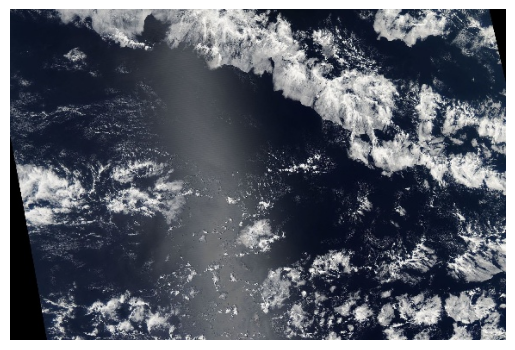

In [ ]:
from pathlib import Path

from src.data.cloud_segmentation_image import CloudSegmentationImage
from src.data.labels import load_processed_labels
from src.visualization.image_display import display_image

# Load the 1st image from train path
TRAIN_PATH = Path('../data/raw/train_images/')
LABELS_PATH = Path('../data/raw/train.csv')

df = load_processed_labels(LABELS_PATH)

# Display the image with ID 4 (in the Labels data frame)
csi = CloudSegmentationImage(df, 4, TRAIN_PATH)
display_image(csi)

**Note by `rosneru`:** Run the next cell multiple times to see other
Augmentation each time. This is because the randomness that is given to the
single transformations with the `p=` arguments.

Original shape: (384, 576, 3), Transformed shape: (384, 576, 3)
..\data\raw\train_images\002be4f.jpg (384, 576, 3) uint8


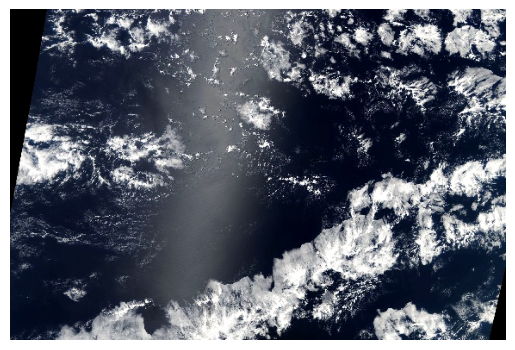

In [19]:
import albumentations as A

image_rgb = csi.get_image_rgb()
image_masks = csi.get_mask_stack()

if image_rgb is not None:
    pipeline = A.Compose(
        [
            A.HorizontalFlip(p=0.3),
            A.VerticalFlip(p=0.3),
            A.RandomBrightnessContrast(p=0.8),
            A.Rotate(p=0.6),
        ]
    )

    # NOTE: The `pipeline()` result, here stored into `transformed_data`, is the
    # albumentations result dictionary. Here, it contains the keys
    # 'image' and 'masks' (because these are the ones we gave in)
    transformed_data = pipeline(image=image_rgb, masks=image_masks)

    transformed_image = transformed_data['image']
    transformed_masks = transformed_data['masks']

    print(
        f'Original shape: {image_rgb.shape}, '
        f'Transformed shape: {transformed_image.shape}'
    )

    csi_augmented = CloudSegmentationImage.from_image_and_masks(
        image_rgb=transformed_image,
        mask_stack=transformed_masks,
        image_name=csi.get_name(),
        image_path=csi.get_image_path().parent,
    )

    display_image(csi_augmented)

## Image 002be4f.jpg

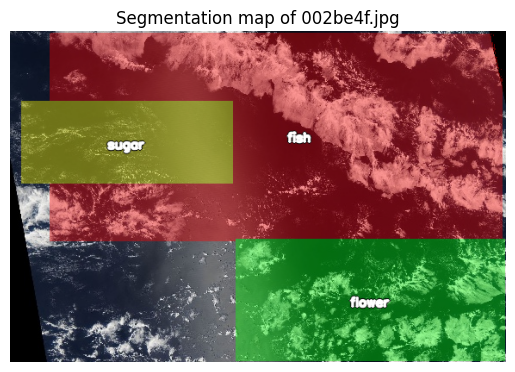

In [ ]:
from IPython.display import Markdown, display

from src.visualization.image_display import display_masks_overlay

# Above, we already had created a CloudSegmentationImage according to ID=4 in
# the labels DataFrame. We Display its name and then the image itself with masks
# overlay.
display(Markdown(f'## Image {csi.get_name()}'))
display_masks_overlay(csi)


## Now augment this image

**Note by `rosneru`:** Run the next cell multiple times to see other
Augmentation each time.

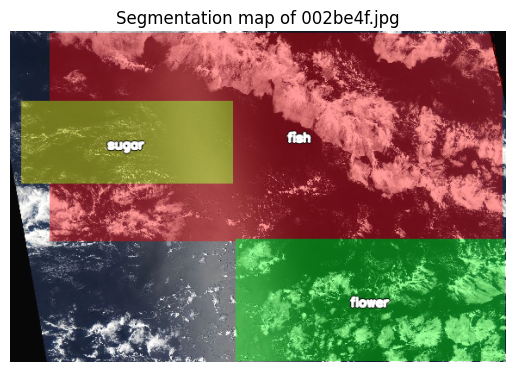

In [29]:
csi = CloudSegmentationImage(df, 4, TRAIN_PATH)

transformed_data = pipeline(
    image=csi.get_image_rgb(), masks=csi.get_mask_stack()
)

transformed_image = transformed_data['image']
transformed_masks = transformed_data['masks']

csi_augmented = CloudSegmentationImage.from_image_and_masks(
    image_rgb=transformed_image,
    mask_stack=transformed_masks,
    image_name=csi.get_name(),
    image_path=csi.get_image_path().parent,
)

display_masks_overlay(csi_augmented)
